# Comparing data-inferred and prior-knowledge GRNs with NCI60

**A 60–90 minute practical.** Compare Pearson and Spearman association networks, the local CollecTRI prior, and a random baseline. Separate three questions: how networks differ, how they agree with curated knowledge, and how well their selected regulators predict held-out expression.

We use **gretapy for network statistics and overlap**, plus a small custom Ridge prediction exercise. NCI60 has RNA data here; this is a reduced TF–gene comparison. The full multimodal GRETA benchmark is described in the [official tutorials](https://gretapy.readthedocs.io/en/latest/notebooks/usage.html).

Install `requirements-lock.txt` in a Python 3.12 environment before class and select its kernel. See [README.md](README.md) for commands, macOS OpenMP setup, interpretation guidance and exercises. The code below downloads no data.

## 1. Inspect the local input and split the cell lines

The RNA table contains log2(FPKM + 1) values. Its existing preprocessing replaced low expression with missing values and filtered genes across the full panel. This module chooses features and fits predictors using training samples, but the input is already preprocessed.

Run cells in order. Paths work with a notebook opened from either this subfolder or the repository root.

In [1]:
from pathlib import Path
import os
import sys
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "cosmos-grn-matplotlib"))
os.environ.setdefault("NUMBA_CACHE_DIR", str(Path(tempfile.gettempdir()) / "cosmos-grn-numba"))
locations = [Path.cwd(), Path.cwd() / "GRN_comparison"]
HERE = next((p for p in locations if (p / "grn_benchmark.py").exists()), None)
if HERE is None:
    raise RuntimeError("Open this notebook from GRN_comparison or the repository root.")
sys.path.insert(0, str(HERE))

import gretapy as gt
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from grn_benchmark import (
    Config, RNA_PATH, prepare_data, infer_networks, prior_agreement,
    evaluate_prediction, plot_comparison, run_benchmark,
)
print("gretapy", gt.__version__)

/private/tmp/cosmos-grn-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gretapy 0.0.3


In [3]:
raw = pd.read_csv(RNA_PATH).set_index("gene")
print(f"{raw.shape[0]:,} genes × {raw.shape[1]} cell lines")
print(f"Missing expression entries: {raw.isna().to_numpy().mean():.1%}")
display(raw.iloc[:5, :8])

11,265 genes × 56 cell lines
Missing expression entries: 18.9%


,786-0,A498,A549/ATCC,ACHN,BT-549,CAKI-1,CCRF-CEM,COLO 205
gene,,,,,,,,
WASH7P,2.564,1.433,1.787,2.846,2.129,1.899,4.149,2.559
LOC729737,NaN,NaN,NaN,1.132,NaN,NaN,NaN,NaN
LOC100133331,NaN,NaN,NaN,4.720,NaN,NaN,1.405,NaN
LOC100288069,1.157,NaN,NaN,1.297,NaN,NaN,NaN,NaN
LINC01128,1.329,NaN,NaN,NaN,1.257,NaN,2.130,NaN


Choose the parameters **before** looking at test performance. By default, use 20 TFs, 500 variable candidate targets, and 10 outgoing edges per TF. Split seed and edge-sampling seed are independent controls.

Targets are selected by training variance among genes observed in at least 80% of training samples. TFs must also occur as sources in the prior and have at least 10 prior edges to these targets. Thus this exercise is conditional on a prior-guided TF universe.

In [4]:
config = Config(
    n_tfs=20,
    n_targets=500,
    edges_per_tf=10,
    test_fraction=0.30,
    split_seed=42,
    network_seed=42,
    alpha=10.0,
)
data = prepare_data(config)
print(f"Training: {len(data['train'])}; test: {len(data['test'])}")
print("TFs:", ", ".join(data["tfs"]))
display(data["gene_info"].head())

Training: 39; test: 17
TFs: ID1, EGR1, SMAD3, TP53, HIF1A, EPAS1, JUN, MYC, KLF6, CEBPB, CTNNB1, SREBF1, AHR, JUND, STAT3, STAT1, HSF1, PPARD, TCF7L2, SREBF2


,gene,is_tf,is_target,train_observed,train_median,train_variance
0,ACOT7,False,True,39,5.214,1.195178
1,ACTN1,False,True,38,5.419,1.391928
2,ACTN4,False,True,39,6.485,1.530956
3,ADGRG1,False,True,32,3.373,2.334638
4,ADK,False,True,39,2.900,1.314534


Median filling uses **training medians only**. Correlation inference uses this filled training matrix, which is a simple approximation for partly censored expression. The separate `train_raw` and `test_raw` tables preserve missing target responses so prediction never scores imputed targets.

**Discuss:** What information did the original expression threshold remove? Could median filling create or weaken an association?

## 2. Build four networks on the same candidate universe

Pearson and Spearman select the strongest absolute training correlations for each TF. The prior has signed annotations rather than a comparable continuous ranking, so sample 10 known edges per TF reproducibly. Random samples 10 candidate targets per TF. All four exclude self-edges.

The direction of correlation edges comes from calling the source a TF. Correlation itself is symmetric; its sign is not an experimentally established regulatory effect.

In [5]:
networks = infer_networks(data, config)
for name, network in networks.items():
    print(f"{name:10s}: {len(network)} edges, "
          f"{network.source.nunique()} TFs, {network.target.nunique()} targets")
display(networks["Pearson"].head(10))

Pearson   : 200 edges, 20 TFs, 148 targets
Spearman  : 200 edges, 20 TFs, 149 targets
CollecTRI : 200 edges, 20 TFs, 103 targets
Random    : 200 edges, 20 TFs, 169 targets


,source,target,score
0,ID1,SLC1A4,-0.593837
1,ID1,ANXA1,0.588736
2,ID1,FSCN1,0.585689
3,ID1,PGRMC1,0.580599
4,ID1,EZR,0.562882
5,ID1,ID3,0.561047
6,ID1,RRAS,0.542329
7,ID1,ODC1,0.524823
8,ID1,EPDR1,0.523096
9,ID1,HSP90AA1,0.519155


Inspect the outgoing-edge budget, then ask whether equal edges also imply equal target coverage. Random matches the TF outgoing degrees; it does not match target incoming degrees.

In [6]:
budgets = pd.DataFrame({name: net.groupby("source").size()
                        for name, net in networks.items()})
display(budgets)
assert budgets.eq(config.edges_per_tf).all().all()

,Pearson,Spearman,CollecTRI,Random
source,,,,
AHR,10,10,10,10
CEBPB,10,10,10,10
CTNNB1,10,10,10,10
EGR1,10,10,10,10
EPAS1,10,10,10,10
HIF1A,10,10,10,10
HSF1,10,10,10,10
ID1,10,10,10,10
JUN,10,10,10,10


## 3. Use gretapy to compare topology and overlap

These public functions accept TF–target edge tables directly, with no CRE column. Zero CRE counts and missing CRE overlaps indicate unavailable chromatin information.

`gt.tl.ocoeff` uses shared unique pairs divided by the size of the smaller edge set. It ignores score signs. A value of 1 can mean containment; it is not evidence that either network is correct.

In [7]:
stats = gt.tl.stats(networks)
overlap = gt.tl.ocoeff(networks)
display(stats)
display(overlap)

,name,n_sources,n_cres,n_targets,n_edges,mean_regulon_size
0,Pearson,20,0,148,200,10.0
1,Spearman,20,0,149,200,10.0
2,CollecTRI,20,0,103,200,10.0
3,Random,20,0,169,200,10.0


,grn_a,grn_b,source,cre,target,edge
0,Pearson,Spearman,1.0,NaN,0.716216,0.590
1,Pearson,CollecTRI,1.0,NaN,0.359223,0.030
2,Pearson,Random,1.0,NaN,0.317568,0.025
3,Spearman,CollecTRI,1.0,NaN,0.407767,0.055
4,Spearman,Random,1.0,NaN,0.355705,0.035
5,CollecTRI,Random,1.0,NaN,0.339806,0.025


Now compare each small selected network against the **full eligible CollecTRI reference**, rather than only against the sampled prior network.

CollecTRI's self-agreement will be 1 by construction. This is circular and cannot rank biological correctness. Unlisted pairs in an incomplete prior are unknown, so the table deliberately uses agreement language rather than treating them as confirmed false positives.

In [8]:
agreement = prior_agreement(networks, data["reference"])
display(agreement)

,name,shared_edges,reference_edges,fraction_in_prior,fraction_of_prior_recovered,self_reference
0,Pearson,15,509,0.075,0.029470,False
1,Spearman,19,509,0.095,0.037328,False
2,CollecTRI,200,509,1.000,0.392927,True
3,Random,10,509,0.050,0.019646,False


## 4. Predict held-out expression using a common model

For each of the same 500 candidate targets, fit a Ridge model using only that network's incoming TFs. The fixed alpha is 10; standardization is fitted on training rows. All networks learn coefficients from the same training observations. Curated signs and correlation scores are not forced into those fitted coefficients.

Use observed training responses to fit and observed test responses to score, requiring at least five in each partition. Targets with no selected parents receive their observed training mean. Keeping those targets in the evaluation makes coverage part of the prediction task.

In [9]:
per_target, prediction_summary = evaluate_prediction(data, networks, config)
display(prediction_summary)
display(per_target.head(10))

,name,n_targets,n_targets_scored,n_targets_with_parents,n_scored_with_parents,n_targets_with_defined_r2,n_targets_with_defined_skill,median_test_r2,mean_skill_vs_train_mean
0,Pearson,500,500,148,148,500,500,-0.079119,0.003050
1,Spearman,500,500,149,149,500,500,-0.081486,0.004475
2,CollecTRI,500,500,103,103,500,500,-0.074506,0.004425
3,Random,500,500,169,169,500,500,-0.082682,0.002896


,name,target,n_parents,n_train_observed,n_test_observed,mse,baseline_mse,mse_ratio_to_mean,r2
0,Pearson,S100A4,0,32,13,7.153938,7.153938,1.000000,-0.122964
1,Pearson,RNA5-8S5,0,39,17,4.474371,4.474371,1.000000,-0.537240
2,Pearson,KRT18,0,35,16,3.619118,3.619118,1.000000,-0.002591
3,Pearson,IFITM3,0,39,17,4.101781,4.101781,1.000000,-0.005476
4,Pearson,MDK,0,39,15,3.475625,3.475625,1.000000,-0.016049
5,Pearson,MT2A,3,39,17,2.594047,3.829720,0.677346,0.321612
6,Pearson,IFITM2,0,33,17,3.436480,3.436480,1.000000,-0.396331
7,Pearson,VIM,0,36,14,6.036190,6.036190,1.000000,-0.090183
8,Pearson,SNHG5,0,39,17,3.164380,3.164380,1.000000,-0.202684
9,Pearson,LGALS3,0,39,14,2.839969,2.839969,1.000000,-0.029190


The main plot reports `1 - mean(MSE_network / MSE_training_mean)` across common eligible targets: zero matches the baseline, positive improves on it, and negative is worse. Each target contributes equally to this average. Its mean baseline is fitted on training responses.

Standard test R² instead uses variation around the test mean. Negative R² is retained; constant test responses have undefined R². Inspect counts and distributions, not just one mean.

r2                     mse_ratio_to_mean                 
          count    median      mean             count median      mean
name                                                                  
Pearson     500 -0.079119 -0.195209               500    1.0  0.996950
Spearman    500 -0.081486 -0.194406               500    1.0  0.995525
CollecTRI   500 -0.074506 -0.193226               500    1.0  0.995575
Random      500 -0.082682 -0.194781               500    1.0  0.997104

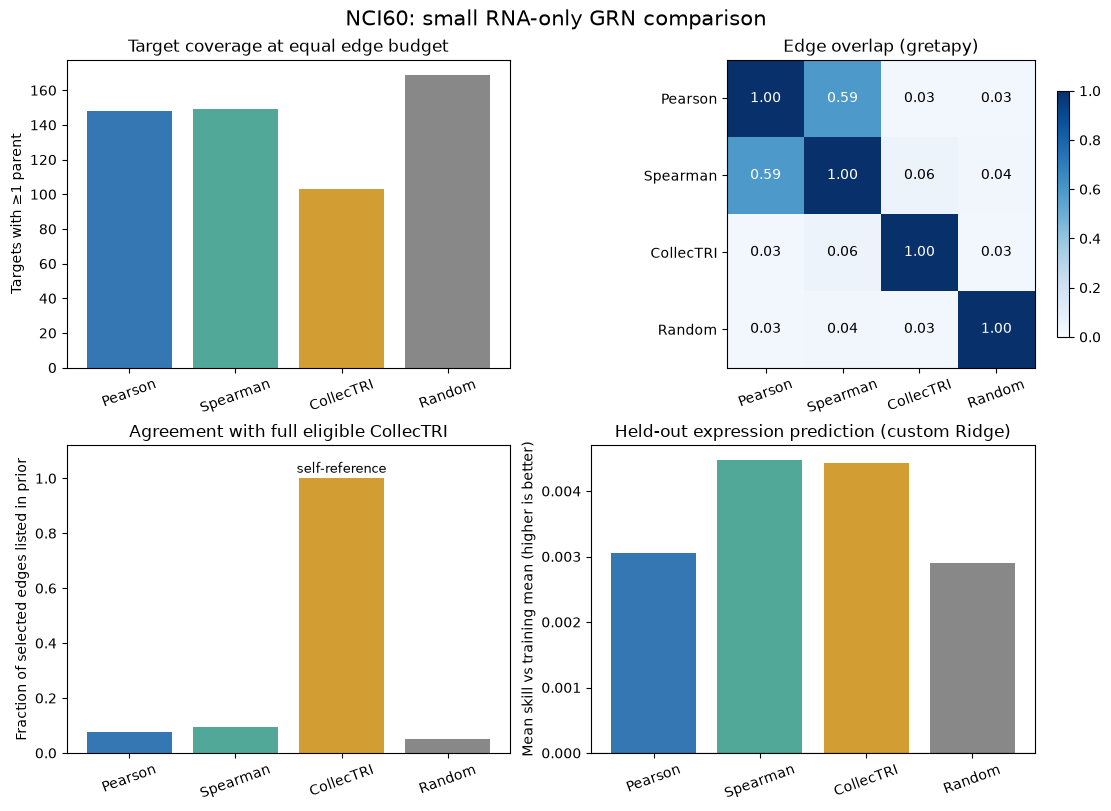

In [10]:
display(per_target.groupby("name", sort=False)[["r2", "mse_ratio_to_mean"]]
        .agg(["count", "median", "mean"]))
figure = plot_comparison(stats, overlap, agreement, prediction_summary)
plt.show()

## 5. Save the run and interpret the evidence

The runner below repeats the same small deterministic analysis and writes the edge lists, split, genes, results, figure, input checksums and package versions. It shares the same functions as the command-line practical. Existing files in the chosen output folder are replaced.

In [ ]:
saved = run_benchmark(config, output_dir=HERE / "results" / "notebook")
plt.close(saved["figure"])
print("Saved to", saved["output_dir"].resolve())
print("Analysis seconds (excluding imports):", saved["run_info"]["elapsed_seconds"])

### Questions and extensions

1. Compare Pearson/Spearman edge overlap with their predictive results. Do the two criteria lead to the same conclusion?
2. Explain why CollecTRI self-agreement is circular. What would an independent edge-level reference require?
3. Change `edges_per_tf` from 10 to 5. Check TF eligibility and coverage before comparing results.
4. Keep `split_seed` fixed and change `network_seed`. Which networks should change, and why?
5. Repeat prespecified sample splits. Treat the variation as sensitivity within this panel, not independent biological replication. If you select a setting using these test scores, reserve new data for a final evaluation.
6. Propose a tissue-aware split or genuine independent TF perturbation experiment. Which confounding factors would each address?

**Interpretation limits:** These are heterogeneous cancer cell lines. Shared tissue programs, indirect regulation and TF activity mechanisms can weaken the link between TF mRNA and direct regulatory action. Good prediction does not prove causation; low overlap does not establish incorrect biology. The preferred support for this prediction task need not be the best prior for COSMOS TF activity estimation.

See [the practical guide](README.md) for command-line exercises and links to the full GRETA evaluation framework.